Predicting Stock Market Prices	Develop and fine-tune a multiple feature Linear Regression model for predicting future TSLA Close prices, incorporating lag features, technical indicators, and ensuring proper feature scaling and multicollinearity checks.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
# Load dataset, sort chronologically, and deduplicate repeated trading dates
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').drop_duplicates(subset=['Date'], keep='last').reset_index(drop=True)

# Anchor all predictors at t-1 (shifted_close) so row t uses strictly historical information
s_close = df['Close'].shift(1)

# 1. Lagged Close & Return Features
df['Close_Lag_1'] = df['Close'].shift(1)
df['Close_Lag_2'] = df['Close'].shift(2)
df['Close_Lag_5'] = df['Close'].shift(5)
df['Log_Return_Lag1'] = np.log(df['Close'].shift(1) / df['Close'].shift(2))
df['Volume_Lag1'] = df['Volume'].shift(1)

# 2. Moving Averages (EMA & SMA)
df['EMA_7'] = s_close.ewm(span=7, adjust=False).mean()
df['SMA_10'] = s_close.rolling(window=10).mean()
df['SMA_20'] = s_close.rolling(window=20).mean()

# 3. Relative Strength Index (RSI-14)
delta = s_close.diff()
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)
avg_gain = gain.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, min_periods=14, adjust=False).mean()
df['RSI_14'] = 100 - (100 / (1 + (avg_gain / avg_loss)))

# 4. MACD (12, 26, 9)
ema_12 = s_close.ewm(span=12, adjust=False).mean()
ema_26 = s_close.ewm(span=26, adjust=False).mean()
df['MACD'] = ema_12 - ema_26
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

# 5. Bollinger Band Width & %B
bb_mid = s_close.rolling(window=20).mean()
bb_std = s_close.rolling(window=20).std()
df['BB_Width'] = (4 * bb_std) / bb_mid
df['BB_PctB'] = (s_close - (bb_mid - 2 * bb_std)) / (4 * bb_std)

# Clean warm-up rows
df_model = df.dropna().reset_index(drop=True)
all_features = [
    'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'EMA_7', 'SMA_10', 'SMA_20',
    'Log_Return_Lag1', 'RSI_14', 'MACD', 'MACD_Signal', 'MACD_Hist',
    'BB_Width', 'BB_PctB', 'Volume_Lag1'
]

print(f"Modeling Dataset Ready: {len(df_model)} rows x {len(all_features)} engineered predictors")

Modeling Dataset Ready: 75 rows x 14 engineered predictors


In [3]:
# Strict 80/20 chronological split
split_idx = int(len(df_model) * 0.80)
train_df = df_model.iloc[:split_idx].copy()
test_df = df_model.iloc[split_idx:].copy()

def calculate_vif(X_df):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_df)
    return pd.DataFrame({
        'Feature': X_df.columns,
        'VIF': [variance_inflation_factor(X_scaled, i) for i in range(X_scaled.shape[1])]
    }).sort_values('VIF', ascending=False).reset_index(drop=True)

# Remove exact algebraic linear dependency first: MACD == MACD_Signal + MACD_Hist (VIF = inf)
selected_features = [f for f in all_features if f != 'MACD']

# Iteratively drop features with VIF > 10 on training data until multicollinearity is resolved
while True:
    vif_table = calculate_vif(train_df[selected_features])
    if vif_table['VIF'].iloc[0] > 10.0 and len(selected_features) > 3:
        dropped = vif_table['Feature'].iloc[0]
        selected_features.remove(dropped)
    else:
        break

print(f"Train Set: {len(train_df)} days ({train_df['Date'].min().date()} to {train_df['Date'].max().date()})")
print(f"Test Set : {len(test_df)} days ({test_df['Date'].min().date()} to {test_df['Date'].max().date()})")
print(f"\nRetained VIF-Pruned Features ({len(selected_features)}): {selected_features}")
print("\n--- Final Training VIF Diagnostics (All < 10) ---")
print(calculate_vif(train_df[selected_features]).round(3).to_string(index=False))

Train Set: 60 days (2025-01-30 to 2025-04-23)
Test Set : 15 days (2025-04-24 to 2025-05-14)

Retained VIF-Pruned Features (7): ['Close_Lag_1', 'Close_Lag_5', 'Log_Return_Lag1', 'MACD_Signal', 'MACD_Hist', 'BB_Width', 'Volume_Lag1']

--- Final Training VIF Diagnostics (All < 10) ---
        Feature   VIF
    Close_Lag_5 7.049
    Close_Lag_1 6.123
    MACD_Signal 5.488
      MACD_Hist 3.124
       BB_Width 3.117
Log_Return_Lag1 1.249
    Volume_Lag1 1.023


In [5]:
def evaluate_predictions(y_true, y_pred, model_name):
    return {
        'Model': model_name,
        'RMSE ($)': round(np.sqrt(mean_squared_error(y_true, y_pred)), 4),
        'MAE ($)': round(mean_absolute_error(y_true, y_pred), 4),
        'MAPE (%)': round(mean_absolute_percentage_error(y_true, y_pred) * 100, 2),
        'R2_Score': round(r2_score(y_true, y_pred), 4)
    }

y_train = train_df['Close']
y_test = test_df['Close']
tscv = TimeSeriesSplit(n_splits=4)
results = []

# 0. Naive Persistence Benchmark (Yesterday's Close = Today's Prediction)
results.append(evaluate_predictions(y_test, test_df['Close_Lag_1'], 'Naive Persistence (Lag-1)'))

# 1. Unregularized OLS on All 14 Collinear Features
scaler_all = StandardScaler()
X_train_all = scaler_all.fit_transform(train_df[all_features])
X_test_all = scaler_all.transform(test_df[all_features])

ols_all = LinearRegression().fit(X_train_all, y_train)
results.append(evaluate_predictions(y_test, ols_all.predict(X_test_all), 'OLS Linear (All 14 Collinear)'))

# 2. Unregularized OLS on VIF-Pruned Features
scaler_vif = StandardScaler()
X_train_vif = scaler_vif.fit_transform(train_df[selected_features])
X_test_vif = scaler_vif.transform(test_df[selected_features])

ols_vif = LinearRegression().fit(X_train_vif, y_train)
results.append(evaluate_predictions(y_test, ols_vif.predict(X_test_vif), 'OLS Linear (7 VIF-Pruned)'))

# 3. Fine-Tuned Ridge Regression (L2 Penalty via TimeSeriesSplit)
ridge_cv = GridSearchCV(Ridge(), {'alpha': np.logspace(-2, 3, 60)}, cv=tscv, scoring='neg_mean_squared_error')
ridge_cv.fit(X_train_all, y_train)
best_ridge = ridge_cv.best_estimator_
results.append(evaluate_predictions(y_test, best_ridge.predict(X_test_all), f"Tuned Ridge (alpha={ridge_cv.best_params_['alpha']:.2f})"))

# 4. Fine-Tuned Lasso Regression (L1 Feature Selection via TimeSeriesSplit)
lasso_cv = GridSearchCV(Lasso(max_iter=50000), {'alpha': np.logspace(-2, 1, 60)}, cv=tscv, scoring='neg_mean_squared_error')
lasso_cv.fit(X_train_vif, y_train)
best_lasso = lasso_cv.best_estimator_
results.append(evaluate_predictions(y_test, best_lasso.predict(X_test_vif), f"Tuned Lasso (alpha={lasso_cv.best_params_['alpha']:.2f})"))

benchmark_df = pd.DataFrame(results).sort_values('RMSE ($)')
print("--- Out-of-Sample Test Set Evaluation ---")
print(benchmark_df.to_string(index=False))

--- Out-of-Sample Test Set Evaluation ---
                        Model  RMSE ($)  MAE ($)  MAPE (%)  R2_Score
     Tuned Ridge (alpha=5.15)    3.3409   2.6368      0.66    0.4045
     Tuned Lasso (alpha=1.94)    3.4325   2.5192      0.63    0.3714
    Naive Persistence (Lag-1)    3.6311   2.8593      0.71    0.2965
    OLS Linear (7 VIF-Pruned)    3.8767   3.3499      0.83    0.1982
OLS Linear (All 14 Collinear)    4.8374   4.0165      1.00   -0.2485


In [6]:
# Compare standardized feature weights across OLS (VIF-Pruned), Tuned Lasso, and Tuned Ridge
coef_df = pd.DataFrame({
    'Feature': selected_features,
    'OLS_VIF_Coef': ols_vif.coef_,
    'Tuned_Lasso_Coef': best_lasso.coef_
}).sort_values('Tuned_Lasso_Coef', key=abs, ascending=False)

ridge_coef_df = pd.DataFrame({
    'Feature': all_features,
    'Tuned_Ridge_Coef': best_ridge.coef_
}).sort_values('Tuned_Ridge_Coef', key=abs, ascending=False)

print("--- Standardized Coefficients: VIF-Pruned OLS vs. Tuned Lasso ---")
print(coef_df.round(4).to_string(index=False))

print("\n--- Standardized Coefficients: Tuned Ridge (All 14 Features) ---")
print(ridge_coef_df.round(4).to_string(index=False))

--- Standardized Coefficients: VIF-Pruned OLS vs. Tuned Lasso ---
        Feature  OLS_VIF_Coef  Tuned_Lasso_Coef
    Close_Lag_1        8.3002             8.305
    Close_Lag_5       -0.6005             0.000
Log_Return_Lag1        0.6521             0.000
    MACD_Signal        2.6956             0.000
      MACD_Hist       -0.8293            -0.000
       BB_Width       -1.3576            -0.000
    Volume_Lag1       -0.2402            -0.000

--- Standardized Coefficients: Tuned Ridge (All 14 Features) ---
        Feature  Tuned_Ridge_Coef
         RSI_14            3.3608
         SMA_20            1.7201
    Close_Lag_1            1.5171
      MACD_Hist           -1.2535
       BB_Width           -1.2288
    Close_Lag_2            1.1839
          EMA_7            0.9823
    MACD_Signal            0.9062
Log_Return_Lag1            0.8240
         SMA_10            0.7356
        BB_PctB            0.5788
    Close_Lag_5            0.4424
           MACD            0.2652
    Volu

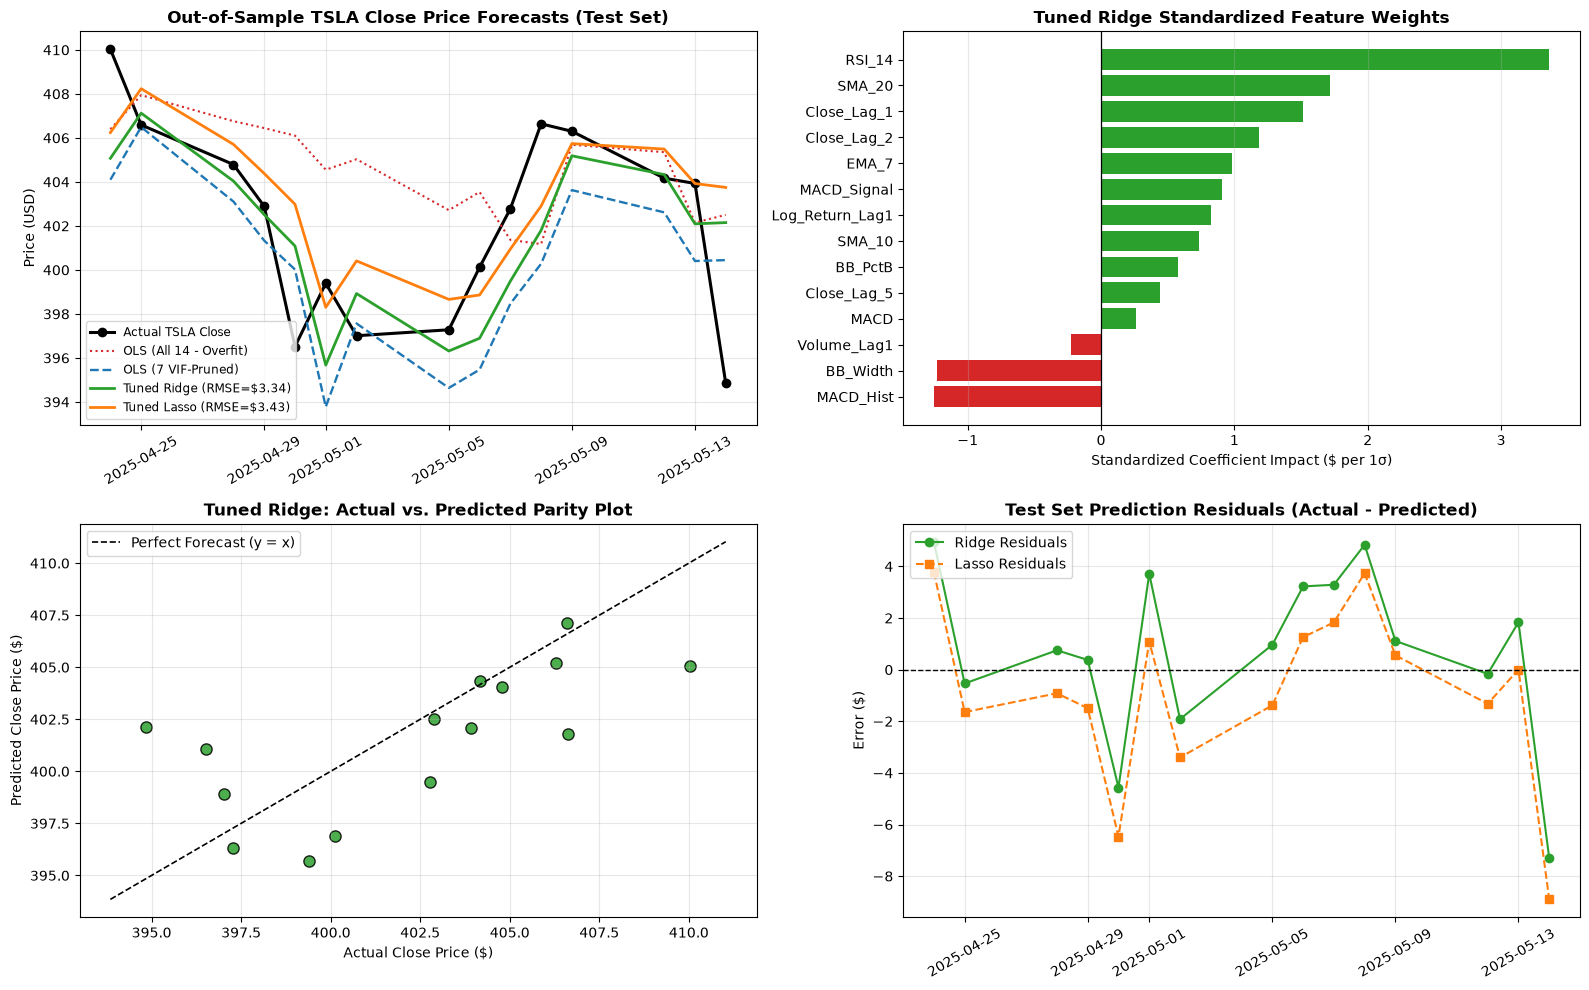

In [7]:
test_dates = test_df['Date']
preds_ols_all = ols_all.predict(X_test_all)
preds_ols_vif = ols_vif.predict(X_test_vif)
preds_ridge = best_ridge.predict(X_test_all)
preds_lasso = best_lasso.predict(X_test_vif)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Actual vs. Predicted Close Prices on Test Window
axes[0, 0].plot(test_dates, y_test, color='black', marker='o', linewidth=2.2, label='Actual TSLA Close')
axes[0, 0].plot(test_dates, preds_ols_all, color='#d62728', linestyle=':', linewidth=1.5, label='OLS (All 14 - Overfit)')
axes[0, 0].plot(test_dates, preds_ols_vif, color='#1f77b4', linestyle='--', linewidth=1.7, label='OLS (7 VIF-Pruned)')
axes[0, 0].plot(test_dates, preds_ridge, color='#2ca02c', linewidth=2.0, label=f"Tuned Ridge (RMSE=${np.sqrt(mean_squared_error(y_test, preds_ridge)):.2f})")
axes[0, 0].plot(test_dates, preds_lasso, color='#ff7f0e', linewidth=2.0, label=f"Tuned Lasso (RMSE=${np.sqrt(mean_squared_error(y_test, preds_lasso)):.2f})")
axes[0, 0].set_title('Out-of-Sample TSLA Close Price Forecasts (Test Set)', fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel('Price (USD)')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 0].legend(loc='lower left', fontsize=8.5)
axes[0, 0].grid(True, alpha=0.3)

# 2. Standardized Feature Weights (Tuned Ridge)
ridge_sorted = ridge_coef_df.sort_values('Tuned_Ridge_Coef', ascending=True)
axes[0, 1].barh(ridge_sorted['Feature'], ridge_sorted['Tuned_Ridge_Coef'],
                color=np.where(ridge_sorted['Tuned_Ridge_Coef'] >= 0, '#2ca02c', '#d62728'))
axes[0, 1].axvline(0, color='black', linewidth=0.9)
axes[0, 1].set_title('Tuned Ridge Standardized Feature Weights', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Standardized Coefficient Impact ($ per 1σ)')
axes[0, 1].grid(axis='x', alpha=0.3)

# 3. Actual vs. Predicted Scatter (Tuned Ridge)
axes[1, 0].scatter(y_test, preds_ridge, color='#2ca02c', s=65, alpha=0.85, edgecolors='black')
lims = [min(y_test.min(), preds_ridge.min()) - 1, max(y_test.max(), preds_ridge.max()) + 1]
axes[1, 0].plot(lims, lims, 'k--', linewidth=1.2, label='Perfect Forecast (y = x)')
axes[1, 0].set_title('Tuned Ridge: Actual vs. Predicted Parity Plot', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Actual Close Price ($)')
axes[1, 0].set_ylabel('Predicted Close Price ($)')
axes[1, 0].legend(loc='upper left')
axes[1, 0].grid(True, alpha=0.3)

# 4. Prediction Residuals Over Time (Tuned Ridge vs. Tuned Lasso)
axes[1, 1].plot(test_dates, y_test - preds_ridge, marker='o', color='#2ca02c', label='Ridge Residuals')
axes[1, 1].plot(test_dates, y_test - preds_lasso, marker='s', color='#ff7f0e', linestyle='--', label='Lasso Residuals')
axes[1, 1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1, 1].set_title('Test Set Prediction Residuals (Actual - Predicted)', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Error ($)')
axes[1, 1].tick_params(axis='x', rotation=30)
axes[1, 1].legend(loc='upper left')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()